# C03 — Molécula a molécula: rarefação, suporte de reads e citocinas

## Objetivo

Usar o `molecule_info.h5` do ressequenciamento para responder, com cada
molécula e o número de reads que a sustenta:

1. em que ponto da curva de saturação a corrida antiga estava;
2. quanto mais ainda renderia sequenciar de novo;
3. quanto da matriz depende de moléculas com 1–2 reads, e se elas são
   artefato;
4. o que tudo isso significa para as citocinas.

## Dados

* `data/allOuts/*/outs/molecule_info.h5` — uma linha por molécula
  (barcode, UMI, gene), com `count` (reads) e `umi_type` (exônica/intrônica);
* células pareadas e contagens da corrida antiga, de C02.

## Método

**Rarefação exata.** Se cada read é mantido com probabilidade *f*, uma
molécula com *c* reads continua visível com probabilidade 1 − (1 − *f*)ᶜ.
Somando sobre as moléculas obtém-se o valor esperado de UMIs, genes e
células positivas em qualquer fração da profundidade atual, sem sorteio.
A extrapolação para o dobro da profundidade usa o estimador de Good–Toulmin
(n₁ − n₂ + n₃ − …), que é um teto: moléculas espúrias de 1 read entram na
conta como se fossem reais.

**Testes de artefato** entre as moléculas de baixo suporte (≤ 2 reads):
erro de UMI (UMI a até 2 bases de uma molécula bem sustentada na mesma
célula e gene), erro de barcode (mesmo gene e UMI noutro barcode com ≥ 10×
mais reads) e troca de índice entre bibliotecas.

## Decisões

* "Baixo suporte" = até 2 reads; "bem sustentada" = 10 reads ou mais. Com
  dezenas de reads por molécula em mediana, são as duas pontas da
  distribuição.
* A passada pelas 14 bibliotecas leva alguns minutos e fica em cache em
  `dataReseq/C03_rarefacao_citocinas/`; `RESEQ_RECOMPUTE=1` força o recálculo.

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import os
import time
import warnings
warnings.filterwarnings("ignore")

import h5py
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from functions import config, fmt as F, io, plotting, rarefaction as rf
from functions.issues import IssueLog, show

plotting.apply_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)

NB = "C03_rarefacao_citocinas"
log = IssueLog(NB)
LIBS = config.LIBRARIES
INK = plotting.INK
PANEL = config.CYTOKINES + config.LINEAGE_TFS
TABELAS = ["resumo", "suporte", "hist_reads", "rarefacao", "limiar_reads",
           "ausencia_na_antiga", "painel", "genes", "troca_de_indice", "barcodes"]

## Passada pelas 14 bibliotecas

In [2]:
pareadas = io.load_data("C02_antigo_vs_novo", "celulas_pareadas")


def calcular() -> dict[str, pd.DataFrame]:
    celulas = {}
    for lib in LIBS:
        with h5py.File(config.outs_dir(lib) / "filtered_feature_bc_matrix.h5", "r") as f:
            celulas[lib] = set(io._dec(f["matrix/barcodes"][()]))
    partes = {t: [] for t in TABELAS}
    t0 = time.time()
    for lib in LIBS:
        res = rf.analyze_library(
            lib, paired=pareadas[pareadas["library_id"] == lib],
            other_cells={l: s for l, s in celulas.items() if l != lib}, panel_genes=PANEL)
        for t in TABELAS:
            partes[t].append(res[t])
    print(f"passada completa em {(time.time() - t0) / 60:.1f} min")
    return {t: pd.concat(partes[t], ignore_index=True) for t in TABELAS}


def carregar() -> dict[str, pd.DataFrame] | None:
    if os.environ.get("RESEQ_RECOMPUTE"):
        return None
    try:
        return {t: io.load_data(NB, f"mol_{t}") for t in TABELAS}
    except FileNotFoundError:
        return None


T = carregar()
if T is None:
    T = calcular()
    for t in TABELAS:
        io.save_data(T[t], NB, f"mol_{t}",
                     description=f"Análise por molécula das 14 bibliotecas: tabela '{t}'")
else:
    print("tabelas lidas do cache em dataReseq/" + NB)

resumo = T["resumo"].set_index("library_id").reindex(LIBS)
print(f"moléculas analisadas: {F.compact(resumo['moleculas'].sum())}; reads: "
      f"{F.compact(resumo['reads_feature'].sum())}")

  CTH92_NS: 16.7 M moléculas, 63 reads/molécula (mediana), f_antiga = 0.233


  CTH92_ML: 15.2 M moléculas, 67 reads/molécula (mediana), f_antiga = 0.180


  CTH94_NS: 86.8 M moléculas, 16 reads/molécula (mediana), f_antiga = 0.090


  CTH94_ML: 11.9 M moléculas, 79 reads/molécula (mediana), f_antiga = 0.255


  CTH97_NS: 20.6 M moléculas, 54 reads/molécula (mediana), f_antiga = 0.178


...

  MB34_NS: 37.8 M moléculas, 33 reads/molécula (mediana), f_antiga = 0.161


  MB34_ML: 19.0 M moléculas, 57 reads/molécula (mediana), f_antiga = 0.263


  HNP44_NS: 4.3 M moléculas, 188 reads/molécula (mediana), f_antiga = 0.282


  HNP44_ML: 40.3 M moléculas, 29 reads/molécula (mediana), f_antiga = 0.140
passada completa em 5.5 min


moléculas analisadas: 465,3 mi; reads: 17,53 bi


In [3]:
# Conferência 1 — as moléculas reproduzem a matriz do Cell Ranger, célula a célula
bc = T["barcodes"]
conf = pareadas.merge(bc[bc["celula"]][["library_id", "barcode", "moleculas"]],
                      on=["library_id", "barcode"], how="left")
assert conf["moleculas"].notna().all()
assert (conf["moleculas"] == conf["umis_nova"]).all(), "molecule_info ≠ matriz filtrada"
print(f"UMIs por célula: molecule_info = matriz filtrada em {F.n(len(conf))} de {F.n(len(conf))} células pareadas")

# Conferência 2 — a rarefação analítica reproduz as curvas de subamostragem do Cell Ranger
rar = T["rarefacao"]
linhas = []
for lib in LIBS:
    ws = io.web_summary_curves(io.load_web_summary(lib))
    r = rar[(rar["library_id"] == lib) & (rar["f"] >= 0.2)]
    for col_a, col_w in [("genes_medianos", "median_genes"), ("umis_medianos", "median_umis"),
                         ("saturacao", "saturation")]:
        cr = np.interp(r["reads_por_celula"], ws["mean_reads_per_cell"], ws[col_w])
        linhas.append({"library_id": lib, "metrica": col_a,
                       "desvio_rel_max": float(np.max(np.abs(r[col_a].to_numpy() - cr) / cr))})
dev = pd.DataFrame(linhas).pivot(index="library_id", columns="metrica", values="desvio_rel_max").reindex(LIBS)
print("maior desvio relativo entre a rarefação analítica e a curva do Cell Ranger (f ≥ 0,2):")
print("  " + "; ".join(f"{c}: {F.pct(dev[c].max(), 1)}" for c in dev.columns))
assert dev.max().max() < 0.03

UMIs por célula: molecule_info = matriz filtrada em 37.092 de 37.092 células pareadas


maior desvio relativo entre a rarefação analítica e a curva do Cell Ranger (f ≥ 0,2):
  genes_medianos: 0,3%; saturacao: 0,0%; umis_medianos: 0,2%


As moléculas reconstroem exatamente a matriz filtrada, e a rarefação em
forma fechada cai sobre as curvas de subamostragem que o próprio Cell Ranger
calcula. O que segue usa essa mesma conta em resoluções que o web summary
não oferece: por célula pareada, por gene e por classe de suporte.

## 1. Quantos reads sustentam cada molécula

In [4]:
sup = T["suporte"].pivot(index="library_id", columns="faixa_reads", values="moleculas_celulas") \
    .reindex(LIBS)[rf.SUPPORT_LABELS]
sup_frac = sup.div(sup.sum(axis=1), axis=0)
tab1 = resumo[["celulas", "moleculas_em_celulas", "reads_por_molecula_mediana",
               "frac_1_read", "frac_ate_2_reads", "frac_exonica", "saturacao_moleculas"]]
io.save_table(tab1.join(sup_frac.add_prefix("frac_reads_")), NB, "suporte_por_biblioteca",
              description="Reads por molécula nas células: mediana e frações por faixa")
F.styler(tab1, {"celulas": F.n, "moleculas_em_celulas": F.compact,
                "reads_por_molecula_mediana": lambda v: F.f(v, 0), "frac_1_read": F.pct,
                "frac_ate_2_reads": F.pct, "frac_exonica": F.pct, "saturacao_moleculas": F.pct})

,celulas,moleculas_em_celulas,reads_por_molecula_mediana,frac_1_read,frac_ate_2_reads,frac_exonica,saturacao_moleculas
library_id,,,,,,,
CTH92_NS,851,"9,1 mi",63,"3,6%","5,6%","67,7%","98,7%"
CTH92_ML,1.570,"8,7 mi",67,"3,5%","5,3%","69,9%","98,8%"
CTH94_NS,6.090,"76,3 mi",16,"6,7%","11,9%","60,1%","95,1%"
CTH94_ML,547,"6,7 mi",79,"3,1%","4,7%","67,9%","98,9%"
CTH97_NS,1.628,"15,0 mi",54,"4,2%","6,1%","73,5%","98,4%"
CTH97_ML,4.737,"16,1 mi",55,"4,4%","6,7%","90,3%","98,6%"
PB20_NS,635,"6,5 mi",107,"3,5%","5,0%","75,8%","99,2%"
PB20_ML,841,"9,4 mi",76,"3,3%","5,0%","77,9%","98,9%"
PB21_NS,4.266,"40,1 mi",14,"7,5%","12,3%","76,4%","94,2%"


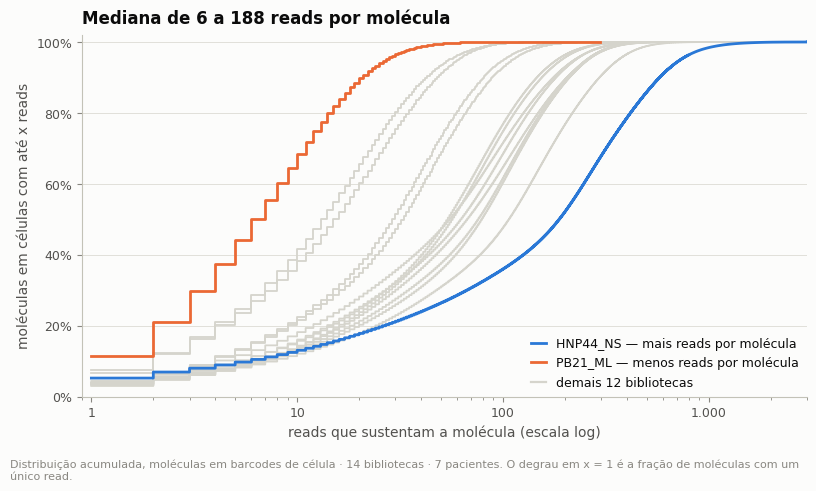

moléculas em células com 1 read: 3,0% a 11,4%; com até 2 reads: 4,7% a 21,1%


In [5]:
hist = T["hist_reads"]
menos = resumo["reads_por_molecula_mediana"].idxmin()
mais = resumo["reads_por_molecula_mediana"].idxmax()
destaque = {mais: plotting.CATEGORICAL[0], menos: plotting.CATEGORICAL[1]}

fig, ax = plt.subplots(figsize=(8.2, 4.6))
for lib in LIBS:
    h = hist[hist["library_id"] == lib].sort_values("reads")
    y = h["moleculas"].cumsum() / h["moleculas"].sum()
    ax.step(h["reads"], y, where="post", color=destaque.get(lib, plotting.CONTEXT),
            lw=2 if lib in destaque else 1.3, zorder=4 if lib in destaque else 2)
ax.set_xscale("log")
ax.set_xlim(0.9, 3000)
ax.set_ylim(0, 1.02)
plotting.percent(ax)
ax.set_xlabel("reads que sustentam a molécula (escala log)")
ax.set_ylabel("moléculas em células com até x reads")
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: F.n(v)))
ax.set_title(f"Mediana de {F.f(resumo['reads_por_molecula_mediana'].min(), 0)} a "
             f"{F.f(resumo['reads_por_molecula_mediana'].max(), 0)} reads por molécula")
handles = [mpl.lines.Line2D([], [], color=destaque[mais], lw=2, label=f"{mais} — mais reads por molécula"),
           mpl.lines.Line2D([], [], color=destaque[menos], lw=2, label=f"{menos} — menos reads por molécula"),
           mpl.lines.Line2D([], [], color=plotting.CONTEXT, lw=1.6, label="demais 12 bibliotecas")]
ax.legend(handles=handles, loc="lower right")
fig.tight_layout()
plotting.note(fig, f"Distribuição acumulada, moléculas em barcodes de célula · {plotting.N_DESIGN}. "
                   "O degrau em x = 1 é a fração de moléculas com um único read.")
plotting.savefig(fig, NB, "reads_por_molecula",
                 description="Distribuição acumulada de reads por molécula nas células",
                 data=hist, data_index=False)
plt.show()

print(f"moléculas em células com 1 read: {F.pct(resumo['frac_1_read'].min())} a "
      f"{F.pct(resumo['frac_1_read'].max())}; com até 2 reads: "
      f"{F.pct(resumo['frac_ate_2_reads'].min())} a {F.pct(resumo['frac_ate_2_reads'].max())}")

**Leitura.** Cada molécula foi lida, em mediana, dezenas a centenas de
vezes. Ainda assim alguns por cento das moléculas têm um único read — o
degrau no início de cada curva. Numa distribuição centrada em dezenas de
reads, uma molécula com 1 read é atípica; as seções 4 e 5 examinam o que
elas são.

## 2. Onde a corrida antiga estava na curva

Para cada biblioteca, procura-se a fração *f* dos reads atuais em que o
total esperado de UMIs nas células pareadas iguala o total observado na
corrida antiga. Se a corrida antiga for uma subamostra da mesma biblioteca,
essa mesma *f* tem de prever também os UMIs e os genes de **cada célula**.

In [6]:
antiga = resumo[["f_antiga", "reads_por_celula_antiga_est", "corr_log_umis_previsto_antigo",
                 "razao_mediana_umis_antigo_previsto", "genes_medianos_obs_antiga",
                 "genes_medianos_previsto_antiga", "razao_mediana_genes_antigo_previsto"]].copy()
antiga["x_profundidade"] = 1 / antiga["f_antiga"]
r1 = rar[rar["f"] == 1.0].set_index("library_id").reindex(LIBS)
r05 = rar[rar["f"] == 0.5].set_index("library_id").reindex(LIBS)
ult = pd.DataFrame({
    "umis_ultima_duplicacao": r1["umis_em_celulas"] / r05["umis_em_celulas"] - 1,
    "genes_ultima_duplicacao": r1["genes_medianos"] / r05["genes_medianos"] - 1,
    "umis_proxima_duplicacao_teto": resumo["gt_moleculas_ao_dobrar"] / resumo["moleculas_em_celulas"],
    "entradas_proxima_duplicacao_teto": resumo["gt_entradas_ao_dobrar"] / resumo["entradas_celula_gene"],
})
# posição da corrida antiga na curva: fração dos UMIs atuais já presentes
antiga["frac_umis_ja_na_antiga"] = resumo["frac_umis_ja_na_antiga"]
io.save_table(antiga.join(ult), NB, "corrida_antiga_na_curva",
              description="Fração de reads equivalente à corrida antiga, previsão por célula e "
                          "retorno da última e da próxima duplicação de profundidade")
F.styler(antiga[["f_antiga", "x_profundidade", "reads_por_celula_antiga_est",
                 "frac_umis_ja_na_antiga", "corr_log_umis_previsto_antigo",
                 "genes_medianos_obs_antiga", "genes_medianos_previsto_antiga"]].join(ult),
         {"f_antiga": lambda v: F.pct(v, 0), "x_profundidade": lambda v: F.x(v, 1),
          "reads_por_celula_antiga_est": F.n, "frac_umis_ja_na_antiga": lambda v: F.pct(v, 0),
          "corr_log_umis_previsto_antigo": lambda v: F.f(v, 4),
          "genes_medianos_obs_antiga": F.n, "genes_medianos_previsto_antiga": F.n,
          "umis_ultima_duplicacao": lambda v: F.pct(v, 1, True),
          "genes_ultima_duplicacao": lambda v: F.pct(v, 1, True),
          "umis_proxima_duplicacao_teto": lambda v: F.pct(v, 1, True),
          "entradas_proxima_duplicacao_teto": lambda v: F.pct(v, 1, True)})

,f_antiga,x_profundidade,reads_por_celula_antiga_est,frac_umis_ja_na_antiga,corr_log_umis_previsto_antigo,genes_medianos_obs_antiga,genes_medianos_previsto_antiga,umis_ultima_duplicacao,genes_ultima_duplicacao,umis_proxima_duplicacao_teto,entradas_proxima_duplicacao_teto
library_id,,,,,,,,,,,
CTH92_NS,23%,"4,3×",459.808,93%,"0,9996",2.974,2.979,"+2,7%","+2,2%","+2,4%","+1,8%"
CTH92_ML,18%,"5,5×",202.719,92%,"0,9998",1.706,1.724,"+2,6%","+2,1%","+2,5%","+2,1%"
CTH94_NS,9%,"11,1×",39.984,67%,"0,9985",2.873,2.937,"+6,0%","+3,6%","+3,9%","+2,6%"
CTH94_ML,26%,"3,9×",665.679,95%,"0,9993",3.256,3.261,"+2,3%","+1,8%","+2,1%","+1,5%"
CTH97_NS,18%,"5,6×",230.190,92%,"0,9995",2.685,2.713,"+3,0%","+2,5%","+3,0%","+3,0%"
CTH97_ML,30%,"3,4×",113.600,94%,"0,9997",949,958,"+3,3%","+3,6%","+3,1%","+3,2%"
PB20_NS,22%,"4,5×",626.533,94%,"0,9997",2.536,2.542,"+2,5%","+1,6%","+2,6%","+2,0%"
PB20_ML,32%,"3,1×",630.157,96%,"0,9997",2.785,2.803,"+2,4%","+2,0%","+2,4%","+1,7%"
PB21_NS,23%,"4,4×",82.357,84%,"0,9938",2.537,2.532,"+6,4%","+5,3%","+4,9%","+5,1%"


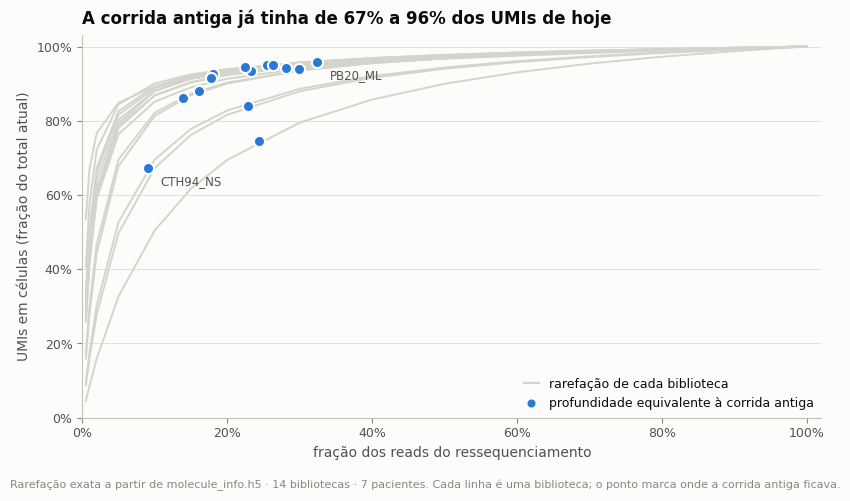

In [7]:
fig, ax = plt.subplots(figsize=(8.4, 4.8))
pts = []
for lib in LIBS:
    r = rar[rar["library_id"] == lib]
    y = r["umis_em_celulas"] / r["umis_em_celulas"].iloc[-1]
    ax.plot(r["f"], y, color=plotting.CONTEXT, lw=1.4, zorder=2)
    fo = antiga.loc[lib, "f_antiga"]
    pts.append((fo, antiga.loc[lib, "frac_umis_ja_na_antiga"]))
ax.plot([p[0] for p in pts], [p[1] for p in pts], "o", ms=8, mfc=plotting.ACCENT,
        mec=INK["surface"], mew=1.5, zorder=4, ls="")
for lib in [antiga["frac_umis_ja_na_antiga"].idxmin(), antiga["frac_umis_ja_na_antiga"].idxmax()]:
    ax.annotate(lib, (antiga.loc[lib, "f_antiga"], antiga.loc[lib, "frac_umis_ja_na_antiga"]),
                textcoords="offset points", xytext=(9, -12), fontsize=8.5, color=INK["secondary"])
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.03)
plotting.percent(ax, "x")
plotting.percent(ax)
ax.set_xlabel("fração dos reads do ressequenciamento")
ax.set_ylabel("UMIs em células (fração do total atual)")
ax.set_title(f"A corrida antiga já tinha de {F.pct(antiga['frac_umis_ja_na_antiga'].min(), 0)} a "
             f"{F.pct(antiga['frac_umis_ja_na_antiga'].max(), 0)} dos UMIs de hoje")
handles = [mpl.lines.Line2D([], [], color=plotting.CONTEXT, lw=1.6, label="rarefação de cada biblioteca"),
           mpl.lines.Line2D([], [], marker="o", ls="", ms=7, mfc=plotting.ACCENT, mec=INK["surface"],
                            mew=1.2, label="profundidade equivalente à corrida antiga")]
ax.legend(handles=handles, loc="lower right")
fig.tight_layout()
plotting.note(fig, f"Rarefação exata a partir de molecule_info.h5 · {plotting.N_DESIGN}. "
                   "Cada linha é uma biblioteca; o ponto marca onde a corrida antiga ficava.")
plotting.savefig(fig, NB, "corrida_antiga_na_curva",
                 description="Curvas de rarefação com a posição equivalente à corrida antiga",
                 data=rar, data_index=False)
plt.show()

In [8]:
print(f"corrida antiga ≈ {F.pct(antiga['f_antiga'].min(), 0)} a {F.pct(antiga['f_antiga'].max(), 0)} "
      f"dos reads atuais (mediana {F.pct(antiga['f_antiga'].median(), 0)}), isto é, o "
      f"ressequenciamento tem de {F.x(antiga['x_profundidade'].min(), 1)} a "
      f"{F.x(antiga['x_profundidade'].max(), 1)} mais reads")
print(f"UMIs por célula previstos × observados na corrida antiga: correlação (log) de "
      f"{F.f(antiga['corr_log_umis_previsto_antigo'].min(), 4)} a "
      f"{F.f(antiga['corr_log_umis_previsto_antigo'].max(), 4)}; genes medianos observados ÷ "
      f"previstos de {F.f(antiga['razao_mediana_genes_antigo_previsto'].min(), 3)} a "
      f"{F.f(antiga['razao_mediana_genes_antigo_previsto'].max(), 3)}")
print(f"última duplicação de profundidade (50% → 100% dos reads): UMIs "
      f"{F.pct(ult['umis_ultima_duplicacao'].min(), 1, True)} a "
      f"{F.pct(ult['umis_ultima_duplicacao'].max(), 1, True)} (mediana "
      f"{F.pct(ult['umis_ultima_duplicacao'].median(), 1, True)})")
print(f"próxima duplicação (Good–Toulmin, teto): UMIs "
      f"{F.pct(ult['umis_proxima_duplicacao_teto'].min(), 1, True)} a "
      f"{F.pct(ult['umis_proxima_duplicacao_teto'].max(), 1, True)} (mediana "
      f"{F.pct(ult['umis_proxima_duplicacao_teto'].median(), 1, True)}); pares célula–gene "
      f"{F.pct(ult['entradas_proxima_duplicacao_teto'].median(), 1, True)} (mediana)")

corrida antiga ≈ 9% a 32% dos reads atuais (mediana 23%), isto é, o ressequenciamento tem de 3,1× a 11,1× mais reads
UMIs por célula previstos × observados na corrida antiga: correlação (log) de 0,9938 a 0,9998; genes medianos observados ÷ previstos de 0,979 a 1,002
última duplicação de profundidade (50% → 100% dos reads): UMIs +2,3% a +11,2% (mediana +3,1%)
próxima duplicação (Good–Toulmin, teto): UMIs +2,1% a +6,1% (mediana +2,6%); pares célula–gene +2,2% (mediana)


**Leitura.** A previsão por célula é quase perfeita: a corrida antiga se
comporta, no nível de célula, como uma fração dos reads das mesmas
bibliotecas. Ela já continha a grande maioria dos UMIs que existem hoje; o
ressequenciamento percorreu o trecho plano da curva.

Olhando para a frente: dobrar outra vez a profundidade renderia, no máximo,
poucos pontos percentuais de UMIs — e esse número é um teto, porque conta
como reais as moléculas de 1 read.

In [9]:
log.add("CRITICAL", "retorno de mais sequenciamento",
        "as bibliotecas estão no platô: a corrida antiga já tinha quase todos os UMIs, e dobrar de novo renderia poucos %",
        evidence=f"corrida antiga equivalente a {F.pct(antiga['f_antiga'].min(), 0)}–"
                 f"{F.pct(antiga['f_antiga'].max(), 0)} dos reads atuais e já com "
                 f"{F.pct(antiga['frac_umis_ja_na_antiga'].min(), 0)}–"
                 f"{F.pct(antiga['frac_umis_ja_na_antiga'].max(), 0)} dos UMIs atuais; última "
                 f"duplicação de profundidade: {F.pct(ult['umis_ultima_duplicacao'].median(), 1, True)} "
                 f"de UMIs (mediana); próxima duplicação, teto de "
                 f"{F.pct(ult['umis_proxima_duplicacao_teto'].median(), 1, True)} (mediana, "
                 f"máx. {F.pct(ult['umis_proxima_duplicacao_teto'].max(), 1, True)})",
        impact="mais sequenciamento destas bibliotecas não muda o dado de forma útil",
        recommendation="encerrar o sequenciamento destas bibliotecas; investir em novas "
                       "capturas com mais células ou em enriquecimento")

## 3. A corrida antiga é uma subamostra exata?

O teste por célula não distingue "mesma biblioteca, menos reads" de "outra
amostragem das mesmas moléculas". O teste por molécula distingue. Tomam-se
os pares (célula, gene) que no ressequenciamento têm **uma única molécula**
e pergunta-se: esse par estava ausente na corrida antiga? Se a antiga fosse
uma subamostra binomial dos mesmos reads, a ausência seria (1 − *f*)ʳ para
uma molécula com *r* reads — praticamente zero acima de ~20 reads.

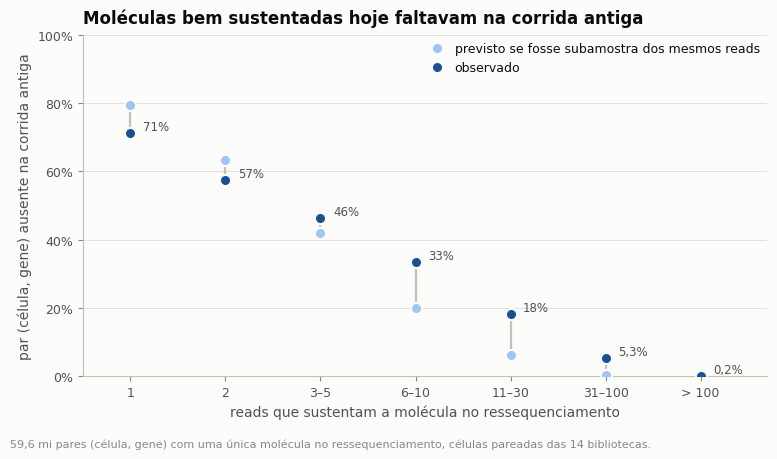

,entradas,observado,previsto_subamostra
faixa_reads,,,
1,5.270.894,"71,19%","79,39%"
2,3.464.113,"57,43%","63,21%"
3–5,7.797.052,"46,47%","42,00%"
6–10,8.695.207,"33,38%","20,06%"
11–30,15.937.349,"18,38%","6,31%"
31–100,13.224.112,"5,29%","0,46%"
> 100,5.186.222,"0,22%","0,00%"


In [10]:
aus = T["ausencia_na_antiga"].groupby("faixa_reads")[["entradas", "ausentes_na_antiga",
                                                      "ausentes_previstas"]].sum() \
    .reindex(rf.SUPPORT_LABELS)
aus["observado"] = aus["ausentes_na_antiga"] / aus["entradas"]
aus["previsto_subamostra"] = aus["ausentes_previstas"] / aus["entradas"]
io.save_table(aus, NB, "ausencia_na_corrida_antiga",
              description="Pares (célula, gene) com 1 molécula na nova: fração ausente na antiga, "
                          "observada e prevista por subamostragem binomial")

fig, ax = plt.subplots(figsize=(7.8, 4.4))
x = np.arange(len(aus))
ax.vlines(x, aus["previsto_subamostra"], aus["observado"], color=INK["axis"], lw=1.6, zorder=1)
ax.plot(x, aus["previsto_subamostra"], "o", ms=8, mfc=plotting.OLD_NEW_COLORS["antiga"],
        mec=INK["surface"], mew=1.5, zorder=3, ls="", label="previsto se fosse subamostra dos mesmos reads")
ax.plot(x, aus["observado"], "o", ms=8, mfc=plotting.OLD_NEW_COLORS["nova"],
        mec=INK["surface"], mew=1.5, zorder=4, ls="", label="observado")
for xi, v in zip(x, aus["observado"]):
    ax.annotate(F.pct(v, 1 if v < 0.1 else 0), (xi, v), textcoords="offset points",
                xytext=(9, 2), fontsize=8.5, color=INK["secondary"])
ax.set_xticks(x)
ax.set_xticklabels(aus.index)
ax.set_xlim(-0.5, len(aus) - 0.3)
ax.set_ylim(0, 1)
plotting.percent(ax)
ax.set_xlabel("reads que sustentam a molécula no ressequenciamento")
ax.set_ylabel("par (célula, gene) ausente na corrida antiga")
ax.set_title("Moléculas bem sustentadas hoje faltavam na corrida antiga")
ax.legend(loc="upper right")
fig.tight_layout()
plotting.note(fig, f"{F.compact(aus['entradas'].sum())} pares (célula, gene) com uma única molécula no "
                   f"ressequenciamento, células pareadas das {config.N_LIBRARIES} bibliotecas.")
plotting.savefig(fig, NB, "ausencia_na_corrida_antiga",
                 description="Ausência na corrida antiga por suporte de reads: observado × previsto",
                 data=aus)
plt.show()
F.styler(aus[["entradas", "observado", "previsto_subamostra"]],
         {"entradas": F.n, "observado": lambda v: F.pct(v, 2), "previsto_subamostra": lambda v: F.pct(v, 2)})

**Leitura.** Para moléculas com 1–5 reads, a ausência na corrida antiga é a
esperada. Mas moléculas com 11–30 reads, que uma subamostra dos mesmos reads
quase nunca perderia, faltavam na corrida antiga numa fração apreciável dos
casos. As duas corridas amostraram as mesmas moléculas com probabilidades
diferentes.

Isso é o esperado se as bibliotecas ressequenciadas vieram de uma **nova
preparação** a partir do mesmo cDNA (cada preparação fragmenta e amplifica
as moléculas de novo), e também pode vir de viés de representação entre
corridas ou plataformas. Os dados não separam as duas explicações; o
registro de bancada, sim. Para a análise, a consequência é a de C02: parte
das detecções de baixa contagem é específica de cada corrida.

In [11]:
log.add("MINOR", "relação entre as duas corridas",
        "a corrida antiga não é uma subamostra exata dos reads atuais: moléculas bem sustentadas hoje faltavam nela",
        evidence="pares (célula, gene) com 1 molécula hoje, ausentes na corrida antiga — "
                 + "; ".join(f"{k} reads: {F.pct(r['observado'], 1)} (previsto {F.pct(r['previsto_subamostra'], 1)})"
                             for k, r in aus.loc[["6–10", "11–30", "31–100"]].iterrows())
                 + f"; no nível de célula a previsão é quase exata (correlação ≥ "
                   f"{F.f(antiga['corr_log_umis_previsto_antigo'].min(), 3)})",
        impact="as duas corridas são amostragens parcialmente independentes das mesmas "
               "moléculas; combinar as contagens das duas não é simplesmente somar reads",
        recommendation="confirmar com quem sequenciou se a biblioteca foi recarregada ou "
                       "preparada de novo a partir do cDNA; usar só o ressequenciamento daqui "
                       "em diante, sem misturar matrizes das duas corridas")

## 4. As moléculas de baixo suporte são artefato?

Três mecanismos conhecidos produzem moléculas falsas com 1–2 reads:

* **erro de UMI** — um read com erro de sequenciamento no UMI vira uma
  "molécula nova" na mesma célula e no mesmo gene, com UMI vizinho do
  original;
* **erro de barcode** — o read cai noutro barcode; aparece como molécula de
  mesmo gene e mesmo UMI de outra, com muito menos reads;
* **troca de índice** entre bibliotecas no sequenciador — os reads trocados
  carregam barcodes de células da biblioteca de origem.

In [12]:
art = resumo[["frac_ate_2_reads", "baixo_suporte_com_parceira", "vizinho_umi_d1",
              "vizinho_umi_d2", "vizinho_umi_ate_2", "vizinho_umi_ate_2_acaso",
              "copia_barcode_celulas_baixo_suporte", "copia_barcode_fundo_baixo_suporte"]].copy()
art["baixo_suporte_explicado_por_umi"] = (
    art["baixo_suporte_com_parceira"] * (art["vizinho_umi_ate_2"] - art["vizinho_umi_ate_2_acaso"]))
art["moleculas_explicadas_por_umi"] = art["baixo_suporte_explicado_por_umi"] * art["frac_ate_2_reads"]

troca = T["troca_de_indice"]
base = troca[troca["origem"] == "demais barcodes de fundo"].set_index("library_id")["moleculas_por_barcode"]
tr = troca[troca["origem"] != "demais barcodes de fundo"].copy()
tr["enriquecimento"] = tr["moleculas_por_barcode"] / tr["library_id"].map(base)
tr["mesmo_paciente"] = [config.patient_of(a) == config.patient_of(b)
                        for a, b in zip(tr["library_id"], tr["origem"])]
art["troca_indice_enriq_mediano"] = tr.groupby("library_id")["enriquecimento"].median()
art["troca_indice_enriq_max"] = tr.groupby("library_id")["enriquecimento"].max()
io.save_table(art, NB, "testes_de_artefato",
              description="Moléculas de baixo suporte: erro de UMI, erro de barcode e troca de índice")
io.save_table(tr, NB, "troca_de_indice_pares",
              description="Moléculas por barcode de fundo que é célula noutra biblioteca", index=False)
F.styler(art[["frac_ate_2_reads", "baixo_suporte_com_parceira", "vizinho_umi_ate_2",
              "vizinho_umi_ate_2_acaso", "baixo_suporte_explicado_por_umi",
              "copia_barcode_celulas_baixo_suporte", "copia_barcode_fundo_baixo_suporte",
              "troca_indice_enriq_mediano", "troca_indice_enriq_max"]],
         {"frac_ate_2_reads": F.pct, "baixo_suporte_com_parceira": lambda v: F.pct(v, 0),
          "vizinho_umi_ate_2": lambda v: F.pct(v, 0), "vizinho_umi_ate_2_acaso": lambda v: F.pct(v, 2),
          "baixo_suporte_explicado_por_umi": lambda v: F.pct(v, 0),
          "copia_barcode_celulas_baixo_suporte": lambda v: F.pct(v, 2),
          "copia_barcode_fundo_baixo_suporte": lambda v: F.pct(v, 0),
          "troca_indice_enriq_mediano": F.x, "troca_indice_enriq_max": F.x})

,frac_ate_2_reads,baixo_suporte_com_parceira,vizinho_umi_ate_2,vizinho_umi_ate_2_acaso,baixo_suporte_explicado_por_umi,copia_barcode_celulas_baixo_suporte,copia_barcode_fundo_baixo_suporte,troca_indice_enriq_mediano,troca_indice_enriq_max
library_id,,,,,,,,,
CTH92_NS,"5,6%",76%,14%,"0,13%",10%,"0,54%",12%,"0,83×","1,64×"
CTH92_ML,"5,3%",66%,18%,"0,11%",11%,"0,56%",14%,"0,83×","1,78×"
CTH94_NS,"11,9%",77%,2%,"0,11%",1%,"0,79%",4%,"0,80×","1,31×"
CTH94_ML,"4,7%",76%,19%,"0,14%",14%,"0,33%",14%,"0,77×","1,36×"
CTH97_NS,"6,1%",66%,13%,"0,32%",8%,"0,61%",7%,"0,84×","1,71×"
CTH97_ML,"6,7%",63%,14%,"0,18%",9%,"0,59%",20%,"0,89×","2,08×"
PB20_NS,"5,0%",74%,25%,"0,19%",18%,"0,73%",19%,"0,83×","1,79×"
PB20_ML,"5,0%",75%,19%,"0,16%",14%,"0,93%",19%,"0,82×","1,83×"
PB21_NS,"12,3%",62%,2%,"0,14%",1%,"0,53%",1%,"0,85×","1,65×"


In [13]:
mesmo = tr[tr["mesmo_paciente"]]["enriquecimento"]
outro = tr[~tr["mesmo_paciente"]]["enriquecimento"]
print(f"moléculas de baixo suporte (≤ 2 reads) nas células: {F.pct(art['frac_ate_2_reads'].min())} a "
      f"{F.pct(art['frac_ate_2_reads'].max())} das moléculas")
print(f"  com molécula bem sustentada do mesmo gene na mesma célula: "
      f"{F.pct(art['baixo_suporte_com_parceira'].min(), 0)} a {F.pct(art['baixo_suporte_com_parceira'].max(), 0)}")
print(f"  dessas, UMI a ≤ 2 bases de uma bem sustentada: {F.pct(art['vizinho_umi_ate_2'].min(), 0)} a "
      f"{F.pct(art['vizinho_umi_ate_2'].max(), 0)} (ao acaso: ≤ {F.pct(art['vizinho_umi_ate_2_acaso'].max(), 2)})")
print(f"  → explicadas por erro de UMI: {F.pct(art['baixo_suporte_explicado_por_umi'].min(), 0)} a "
      f"{F.pct(art['baixo_suporte_explicado_por_umi'].max(), 0)} das de baixo suporte "
      f"= {F.pct(art['moleculas_explicadas_por_umi'].min(), 1)} a "
      f"{F.pct(art['moleculas_explicadas_por_umi'].max(), 1)} de todas as moléculas")
print(f"erro de barcode: {F.pct(art['copia_barcode_celulas_baixo_suporte'].min(), 2)} a "
      f"{F.pct(art['copia_barcode_celulas_baixo_suporte'].max(), 2)} das de baixo suporte nas células; "
      f"no fundo, {F.pct(art['copia_barcode_fundo_baixo_suporte'].min(), 0)} a "
      f"{F.pct(art['copia_barcode_fundo_baixo_suporte'].max(), 0)}")
print(f"troca de índice: moléculas por barcode de fundo que é célula noutra biblioteca ÷ demais "
      f"barcodes de fundo — outro paciente: mediana {F.x(outro.median())} "
      f"(percentis 5–95: {F.x(outro.quantile(.05))} a {F.x(outro.quantile(.95))}); mesmo paciente: "
      f"mediana {F.x(mesmo.median())}")

moléculas de baixo suporte (≤ 2 reads) nas células: 4,7% a 21,1% das moléculas
  com molécula bem sustentada do mesmo gene na mesma célula: 62% a 78%
  dessas, UMI a ≤ 2 bases de uma bem sustentada: 0% a 28% (ao acaso: ≤ 0,32%)
  → explicadas por erro de UMI: 0% a 21% das de baixo suporte = 0,1% a 1,4% de todas as moléculas
erro de barcode: 0,16% a 0,93% das de baixo suporte nas células; no fundo, 1% a 20%
troca de índice: moléculas por barcode de fundo que é célula noutra biblioteca ÷ demais barcodes de fundo — outro paciente: mediana 0,83× (percentis 5–95: 0,72× a 1,69×); mesmo paciente: mediana 0,89×


**Leitura.**

* *Erro de UMI* existe e é mensurável: entre as moléculas de baixo suporte
  que têm, na mesma célula e gene, uma molécula bem sustentada, uma fração
  muito acima do acaso tem UMI vizinho dela. O peso cresce com a saturação —
  é visível nas bibliotecas lidas centenas de vezes e some nas menos
  saturadas. Em todas, explica só uma parte minoritária das moléculas de
  baixo suporte, e essas moléculas inflam a contagem de um gene que a célula
  já expressava — não criam célula positiva.
* *Erro de barcode* é desprezível dentro das células; ele joga os reads em
  barcodes de fundo, onde responde por uma parte visível das moléculas de 1–2
  reads.
* *Troca de índice* não aparece: barcodes de fundo que são célula em outra
  biblioteca não têm mais moléculas que os demais.

A maior parte das moléculas de baixo suporte **não é explicada por esses três
mecanismos**. Sobram duas possibilidades que estes testes não separam:
moléculas reais pouco amplificadas — a cauda que o próximo aumento de
profundidade "descobriria" — e quimeras formadas na amplificação, que juntam
o barcode de uma molécula ao cDNA de outra e só seriam identificáveis com os
alinhamentos. A seção 6 mostra que pelo menos parte delas é comprovadamente
espúria.

In [14]:
log.add("INFO", "moléculas de baixo suporte (1–2 reads)",
        "[verificado] erro de UMI e de barcode explicam só uma minoria das moléculas de 1–2 reads",
        evidence=f"{F.pct(art['frac_ate_2_reads'].min())}–{F.pct(art['frac_ate_2_reads'].max())} das "
                 f"moléculas em células têm até 2 reads; erro de UMI explica "
                 f"{F.pct(art['baixo_suporte_explicado_por_umi'].min(), 0)}–"
                 f"{F.pct(art['baixo_suporte_explicado_por_umi'].max(), 0)} delas (mais nas bibliotecas "
                 f"mais saturadas); erro de barcode ≤ {F.pct(art['copia_barcode_celulas_baixo_suporte'].max(), 2)}",
        impact="o restante mistura moléculas reais pouco amplificadas e leitura espúria (seção 6); "
               "um filtro geral por suporte removeria as duas coisas",
        recommendation="não filtrar toda a matriz por suporte de reads; usar o suporte onde ele "
                       "decide — chamada de positividade em genes de baixa contagem (seção 7) e "
                       "exclusão dos genes dominados por reads isolados (seção 6)")
log.add("INFO", "troca de índice entre bibliotecas",
        "[verificado e descartado] não há sinal de index hopping entre as 14 bibliotecas",
        evidence=f"barcodes de fundo que são célula em biblioteca de outro paciente têm "
                 f"{F.x(outro.median())} as moléculas dos demais barcodes de fundo (mediana de "
                 f"{len(outro)} pares de bibliotecas)",
        impact="a fração de reads fora de células vem de RNA ambiente e de barcodes de baixo "
               "conteúdo da própria biblioteca, não de contaminação entre bibliotecas no "
               "sequenciador",
        recommendation="nenhuma")

## 5. E se a matriz exigisse mais de um read por UMI?

In [15]:
lim = T["limiar_reads"].pivot(index="library_id", columns="min_reads",
                              values=["umis_medianos", "genes_medianos", "entradas"]).reindex(LIBS)
efeito = pd.DataFrame({
    "umis_k2": lim[("umis_medianos", 2)] / lim[("umis_medianos", 1)] - 1,
    "umis_k3": lim[("umis_medianos", 3)] / lim[("umis_medianos", 1)] - 1,
    "genes_k2": lim[("genes_medianos", 2)] / lim[("genes_medianos", 1)] - 1,
    "genes_k3": lim[("genes_medianos", 3)] / lim[("genes_medianos", 1)] - 1,
    "pares_k2": lim[("entradas", 2)] / lim[("entradas", 1)] - 1,
})
io.save_table(efeito, NB, "efeito_do_limiar_de_reads",
              description="Variação de UMIs, genes e pares célula–gene ao exigir ≥2 ou ≥3 reads por UMI")
print(f"exigir ≥ 2 reads por UMI: UMIs medianos {F.pct(efeito['umis_k2'].max(), 1, True)} a "
      f"{F.pct(efeito['umis_k2'].min(), 1, True)}; genes medianos {F.pct(efeito['genes_k2'].max(), 1, True)} a "
      f"{F.pct(efeito['genes_k2'].min(), 1, True)}; pares célula–gene "
      f"{F.pct(efeito['pares_k2'].max(), 1, True)} a {F.pct(efeito['pares_k2'].min(), 1, True)}")
F.styler(efeito, {c: (lambda v: F.pct(v, 1, True)) for c in efeito.columns})

exigir ≥ 2 reads por UMI: UMIs medianos -2,8% a -11,4%; genes medianos -2,2% a -8,1%; pares célula–gene -2,3% a -8,0%


,umis_k2,umis_k3,genes_k2,genes_k3,pares_k2
library_id,,,,,
CTH92_NS,"-3,4%","-5,2%","-2,8%","-4,0%","-2,8%"
CTH92_ML,"-3,7%","-5,6%","-2,8%","-4,2%","-3,0%"
CTH94_NS,"-6,8%","-12,0%","-4,5%","-7,7%","-4,3%"
CTH94_ML,"-2,9%","-4,5%","-2,2%","-3,8%","-2,3%"
CTH97_NS,"-4,0%","-5,9%","-4,0%","-5,7%","-4,1%"
CTH97_ML,"-4,5%","-7,0%","-5,1%","-7,2%","-4,5%"
PB20_NS,"-3,3%","-4,7%","-2,3%","-3,3%","-2,8%"
PB20_ML,"-3,2%","-4,8%","-2,7%","-4,0%","-2,6%"
PB21_NS,"-7,0%","-11,6%","-7,4%","-10,9%","-8,0%"


O filtro custaria alguns por cento de UMIs e de genes por célula — mais nas
bibliotecas menos saturadas, onde 1–2 reads é mais frequentemente uma
molécula real pouco amostrada. Como a seção 4 não encontrou artefato que o
justifique, ele fica como opção de análise de sensibilidade, não como etapa
do pré-processamento.

## 6. Genes sustentados por reads isolados

Para a maioria dos genes, poucas moléculas têm baixo suporte. Um gene em que
a **maioria** das moléculas tem 1–2 reads — e são intrônicas — não se parece
com um transcrito amplificado.

In [16]:
ref = io.reference_features()
g = T["genes"].groupby("gene_idx")[["moleculas", "baixo_suporte", "exonicas"]].sum()
g.insert(0, "gene", ref["gene_name"].to_numpy()[g.index])
g.insert(1, "gene_id", ref["gene_id"].to_numpy()[g.index])
g["frac_baixo_suporte"] = g["baixo_suporte"] / g["moleculas"]
g["frac_exonica"] = g["exonicas"] / g["moleculas"]
g = g.set_index("gene_id")          # o símbolo não é único na referência; o Ensembl ID é
global_low = g["baixo_suporte"].sum() / g["moleculas"].sum()
suspeitos = g[(g["moleculas"] >= 200) & (g["frac_baixo_suporte"] >= 0.5)] \
    .sort_values("moleculas", ascending=False)
io.save_table(suspeitos, NB, "genes_sustentados_por_reads_isolados",
              description="Genes com ≥200 moléculas em células das quais ≥50% têm até 2 reads")

colapso = pd.read_csv(config.TABLES / "C02_antigo_vs_novo" / "genes_que_colapsaram.csv", index_col=0)
em_comum = sorted(set(suspeitos.index) & set(colapso["gene_id"]))
col_g = g.reindex(colapso["gene_id"]).dropna(subset=["moleculas"])
print(f"fração global de moléculas de baixo suporte: {F.pct(global_low)}")
print(f"genes com ≥ 200 moléculas e ≥ 50% de baixo suporte: {F.n(len(suspeitos))} "
      f"(somam {F.pct(suspeitos['moleculas'].sum() / g['moleculas'].sum(), 3)} das moléculas); "
      f"fração exônica mediana {F.pct(suspeitos['frac_exonica'].median(), 0)} contra "
      f"{F.pct(g['exonicas'].sum() / g['moleculas'].sum(), 0)} no conjunto")
print(f"dos {len(colapso)} genes que colapsaram entre corridas (C02), {len(em_comum)} estão nesta lista; "
      f"entre eles, baixo suporte mediano de {F.pct(col_g['frac_baixo_suporte'].median(), 0)} e "
      f"fração exônica mediana de {F.pct(col_g['frac_exonica'].median(), 0)}")
F.styler(suspeitos.head(15).set_index("gene")[["moleculas", "frac_baixo_suporte", "frac_exonica"]],
         {"moleculas": F.n, "frac_baixo_suporte": lambda v: F.pct(v, 0), "frac_exonica": lambda v: F.pct(v, 0)})

fração global de moléculas de baixo suporte: 12,3%
genes com ≥ 200 moléculas e ≥ 50% de baixo suporte: 988 (somam 0,366% das moléculas); fração exônica mediana 1% contra 73% no conjunto
dos 85 genes que colapsaram entre corridas (C02), 48 estão nesta lista; entre eles, baixo suporte mediano de 82% e fração exônica mediana de 1%


,moleculas,frac_baixo_suporte,frac_exonica
gene,,,
LINC00486,215.974,97%,0%
SLC26A3,103.248,99%,0%
STEAP1B,47.530,92%,0%
GPM6A,33.575,99%,0%
SNHG31,21.800,51%,0%
ZNF385D,17.712,89%,1%
LMOD3,15.269,91%,98%
MCTP1,11.629,86%,4%
ENSG00000246225,10.808,54%,5%


In [17]:
# Em que bibliotecas essas moléculas estão
gl = T["genes"].merge(pd.DataFrame({"gene_idx": np.arange(len(ref)), "gene_id": ref["gene_id"]}),
                      on="gene_idx")
sus_lib = gl[gl["gene_id"].isin(suspeitos.index)].groupby("library_id")["moleculas"].sum().reindex(LIBS)
dist = pd.DataFrame({
    "moleculas": sus_lib, "por_celula": sus_lib / resumo["celulas"],
    "frac_das_moleculas_da_biblioteca": sus_lib / resumo["moleculas_em_celulas"],
    "parcela_do_total": sus_lib / sus_lib.sum()})
io.save_table(dist, NB, "reads_isolados_por_biblioteca",
              description="Moléculas dos genes sustentados por reads isolados, por biblioteca")
F.styler(dist, {"moleculas": F.n, "por_celula": lambda v: F.f(v, 0),
                "frac_das_moleculas_da_biblioteca": lambda v: F.pct(v, 2),
                "parcela_do_total": lambda v: F.pct(v, 0)})

,moleculas,por_celula,frac_das_moleculas_da_biblioteca,parcela_do_total
library_id,,,,
CTH92_NS,19.968,23,"0,22%",1%
CTH92_ML,27.186,17,"0,31%",2%
CTH94_NS,120.255,20,"0,16%",9%
CTH94_ML,15.205,28,"0,23%",1%
CTH97_NS,106.354,65,"0,71%",8%
CTH97_ML,79.616,17,"0,49%",6%
PB20_NS,28.871,45,"0,44%",2%
PB20_ML,28.968,34,"0,31%",2%
PB21_NS,556.279,130,"1,39%",41%


### Controle negativo: genes do cromossomo Y em doadoras

Cinco dos sete pacientes são mulheres (C02). Nas bibliotecas delas, uma
molécula atribuída a um gene do Y não pode ser expressão: é, por construção,
atribuição espúria. Isso dá uma amostra de moléculas sabidamente falsas, e
permite ver como elas se parecem.

In [18]:
yi = io.gene_index(ref["gene_name"], config.Y_GENES)
gy = T["genes"][T["genes"]["gene_idx"].isin(list(yi.values()))].copy()
gy["gene"] = ref["gene_name"].to_numpy()[gy["gene_idx"]]
gy["sexo"] = [config.PATIENT_SEX[config.patient_of(l)] for l in gy["library_id"]]
ctrl = gy.groupby(["gene", "sexo"])[["moleculas", "baixo_suporte", "exonicas"]].sum().unstack(fill_value=0)
ncel = resumo.groupby([config.PATIENT_SEX[config.patient_of(l)] for l in resumo.index])["celulas"].sum()
tot_y = gy.groupby("sexo")[["moleculas", "baixo_suporte", "exonicas"]].sum()
tot_y["por_celula"] = tot_y["moleculas"] / ncel
tot_y["frac_baixo_suporte"] = tot_y["baixo_suporte"] / tot_y["moleculas"]
tot_y["frac_exonica"] = tot_y["exonicas"] / tot_y["moleculas"]
y_lib = gy.groupby("library_id")[["moleculas", "baixo_suporte"]].sum().reindex(LIBS)
y_lib["por_celula"] = y_lib["moleculas"] / resumo["celulas"]
y_fem = y_lib[[config.PATIENT_SEX[config.patient_of(l)] == "feminino" for l in y_lib.index]]
xist_idx = io.gene_index(ref["gene_name"], ["XIST"])["XIST"]
gx = T["genes"][T["genes"]["gene_idx"] == xist_idx].copy()
gx["sexo"] = [config.PATIENT_SEX[config.patient_of(l)] for l in gx["library_id"]]
xist = gx.groupby("sexo")["moleculas"].sum()
io.save_table(tot_y, NB, "controle_genes_do_Y",
              description="Moléculas atribuídas a genes do Y em bibliotecas de doadoras e de doadores")

print(f"genes do Y avaliados: {len(yi)}")
for sx in ("feminino", "masculino"):
    r = tot_y.loc[sx]
    print(f"  doador {sx}: {F.n(r['moleculas'])} moléculas ({F.f(r['por_celula'], 2)} por célula); "
          f"com 1–2 reads: {F.pct(r['frac_baixo_suporte'])}; exônicas: {F.pct(r['frac_exonica'])}")
print(f"  por biblioteca de doadora: de {F.f(y_fem['por_celula'].min(), 2)} a "
      f"{F.f(y_fem['por_celula'].max(), 2)} moléculas por célula (máximo em {y_fem['por_celula'].idxmax()})")
print(f"controle espelhado — XIST: {F.n(xist.get('feminino', 0))} moléculas em doadoras, "
      f"{F.n(xist.get('masculino', 0))} em doadores")
print(f"fração global de moléculas com 1–2 reads, para referência: {F.pct(global_low)}")

genes do Y avaliados: 14
  doador feminino: 15.761 moléculas (0,56 por célula); com 1–2 reads: 97,8%; exônicas: 0,3%
  doador masculino: 81.412 moléculas (8,54 por célula); com 1–2 reads: 10,1%; exônicas: 59,9%
  por biblioteca de doadora: de 0,09 a 3,05 moléculas por célula (máximo em PB21_NS)
controle espelhado — XIST: 49.284 moléculas em doadoras, 5 em doadores
fração global de moléculas com 1–2 reads, para referência: 12,3%


**Leitura.** Existe um grupo de genes cuja contagem é feita quase só de
moléculas intrônicas com 1–2 reads. Ele inclui boa parte dos genes que
colapsaram entre as corridas em C02, e se concentra em poucas bibliotecas —
sobretudo PB21_NS.

O controle do cromossomo Y mostra o que essas moléculas são. Em doadoras,
onde um gene do Y não pode estar expresso, quase todas as moléculas
atribuídas a ele têm 1–2 reads e nenhuma é exônica; em doadores, as moléculas
dos mesmos genes são exônicas e bem sustentadas. O controle espelhado
descarta contaminação entre bibliotecas: XIST praticamente não aparece em
doadores. Ou seja: **nesta base, molécula sabidamente falsa tem cara de
molécula intrônica de 1–2 reads**, e não vem de outra amostra.

Isso não torna falsa toda molécula de baixo suporte (seção 4), mas dá o
critério prático: uma detecção sustentada só por 1–2 reads é a menos
confiável que a matriz contém.

In [19]:
log.add("MINOR", "genes sustentados por reads isolados",
        "um grupo de genes tem contagem feita quase só de moléculas intrônicas com 1–2 reads, concentrada em poucas bibliotecas",
        evidence=f"{F.n(len(suspeitos))} genes com ≥ 200 moléculas e ≥ 50% de baixo suporte (global: "
                 f"{F.pct(global_low)}), fração exônica mediana de "
                 f"{F.pct(suspeitos['frac_exonica'].median(), 0)}; ex.: "
                 + ", ".join(suspeitos["gene"].head(5))
                 + f"; {F.pct(suspeitos['moleculas'].sum() / g['moleculas'].sum(), 2)} das moléculas no "
                   f"total, mas {F.pct(dist['frac_das_moleculas_da_biblioteca'].max(), 1)} em "
                   f"{dist['frac_das_moleculas_da_biblioteca'].idxmax()} ({F.pct(dist['parcela_do_total'].max(), 0)} "
                   f"do total); {len(em_comum)} dos {len(colapso)} genes que colapsaram entre corridas estão aqui",
        impact="contagem que não se comporta como expressão e é específica de bibliotecas: "
               "candidata a entrar em HVGs e marcadores como efeito de batch",
        recommendation="excluir esta lista da seleção de HVGs e não usar esses genes como "
                       "marcadores (tables/C03_rarefacao_citocinas/genes_sustentados_por_reads_isolados.csv)")
log.add("INFO", "controle negativo — genes do Y em doadoras",
        "[verificado] moléculas sabidamente espúrias são intrônicas e de 1–2 reads; não há contaminação entre bibliotecas",
        evidence=f"genes do Y em bibliotecas de doadoras: {F.n(tot_y.loc['feminino', 'moleculas'])} "
                 f"moléculas, {F.pct(tot_y.loc['feminino', 'frac_baixo_suporte'])} com 1–2 reads e "
                 f"{F.pct(tot_y.loc['feminino', 'frac_exonica'])} exônicas; em doadores, "
                 f"{F.pct(tot_y.loc['masculino', 'frac_baixo_suporte'])} com 1–2 reads e "
                 f"{F.pct(tot_y.loc['masculino', 'frac_exonica'])} exônicas; XIST em doadores: "
                 f"{F.n(xist.get('masculino', 0))} moléculas contra {F.n(xist.get('feminino', 0))} em doadoras",
        impact="o suporte de reads separa detecção confiável de espúria nos genes de baixa contagem",
        recommendation="ao chamar célula positiva para um gene raro, exigir molécula com ≥ 3 reads")

## 7. Citocinas

Duas perguntas: mais profundidade traria mais células positivas? E as que
existem hoje, com que suporte foram chamadas? Pela seção 6, uma célula é
contada como positiva **com suporte** quando tem ao menos uma molécula do
gene com 3 reads ou mais.

In [20]:
painel = T["painel"]
n_cel = int(resumo["celulas"].sum())
SUPORTE_MIN = 3

linhas = []
for gname in PANEL:
    p = painel[painel["gene"] == gname]
    if p.empty:
        continue
    h = np.bincount(p["reads"].to_numpy(dtype=np.int64))
    pos = len(p)
    linhas.append({
        "gene": gname, "celulas_positivas": pos, "pct_celulas": pos / n_cel,
        "positivas_com_suporte": int((p["reads_max"] >= SUPORTE_MIN).sum()),
        "umis": int(p["umis"].sum()), "umis_por_cel_pos": p["umis"].mean(),
        "reads_medianos_por_cel_pos": float(p["reads"].median()),
        "so_1_2_reads": float((p["reads_max"] <= 2).mean()),
        "de_3_a_9_reads": float(((p["reads_max"] > 2) & (p["reads_max"] < 10)).mean()),
        "dez_ou_mais_reads": float((p["reads_max"] >= 10).mean()),
        "positivas_com_metade_dos_reads": rf.expected_from_hist(h, 0.5),
        "positivas_com_25pct_dos_reads": rf.expected_from_hist(h, 0.25),
        "novas_ao_dobrar_teto": rf.good_toulmin_doubling(h),
    })
cit = pd.DataFrame(linhas).set_index("gene")
cit["pct_com_suporte"] = cit["positivas_com_suporte"] / n_cel
cit["ganho_ultima_duplicacao"] = cit["celulas_positivas"] / cit["positivas_com_metade_dos_reads"] - 1
cit["ganho_proxima_duplicacao_teto"] = cit["novas_ao_dobrar_teto"] / cit["celulas_positivas"]
io.save_table(cit, NB, "citocinas_suporte_e_rarefacao",
              description="Citocinas e TFs: suporte de reads das células positivas e rarefação")
F.styler(cit[["celulas_positivas", "pct_celulas", "positivas_com_suporte", "pct_com_suporte",
              "umis_por_cel_pos", "reads_medianos_por_cel_pos", "so_1_2_reads", "dez_ou_mais_reads",
              "ganho_ultima_duplicacao", "ganho_proxima_duplicacao_teto"]],
         {"celulas_positivas": F.n, "pct_celulas": lambda v: F.pct(v, 2),
          "positivas_com_suporte": F.n, "pct_com_suporte": lambda v: F.pct(v, 2),
          "umis_por_cel_pos": lambda v: F.f(v, 1), "reads_medianos_por_cel_pos": F.n,
          "so_1_2_reads": lambda v: F.pct(v, 0), "dez_ou_mais_reads": lambda v: F.pct(v, 0),
          "ganho_ultima_duplicacao": lambda v: F.pct(v, 1, True),
          "ganho_proxima_duplicacao_teto": lambda v: F.pct(v, 1, True)})

,celulas_positivas,pct_celulas,positivas_com_suporte,pct_com_suporte,umis_por_cel_pos,reads_medianos_por_cel_pos,so_1_2_reads,dez_ou_mais_reads,ganho_ultima_duplicacao,ganho_proxima_duplicacao_teto
gene,,,,,,,,,,
IFNG,1.125,"2,97%",978,"2,58%","15,2",44,13%,73%,"+6,5%","+5,2%"
TNF,2.384,"6,29%",2.060,"5,44%","1,8",19,14%,63%,"+6,7%","+6,0%"
IL2,101,"0,27%",83,"0,22%","30,9",20,18%,64%,"+9,3%","+10,9%"
IL4,106,"0,28%",95,"0,25%","1,1",17,10%,58%,"+5,6%","+13,2%"
IL5,325,"0,86%",280,"0,74%","1,4",17,14%,61%,"+6,7%","-4,6%"
IL9,144,"0,38%",116,"0,31%","16,0",141,19%,67%,"+9,7%","+15,3%"
IL10,60,"0,16%",50,"0,13%","1,4",18,17%,63%,"+6,8%","+10,0%"
IL13,71,"0,19%",56,"0,15%","4,0",18,21%,61%,"+9,8%","-4,2%"
IL17A,81,"0,21%",75,"0,20%","9,1",274,7%,86%,"+3,7%","-6,2%"


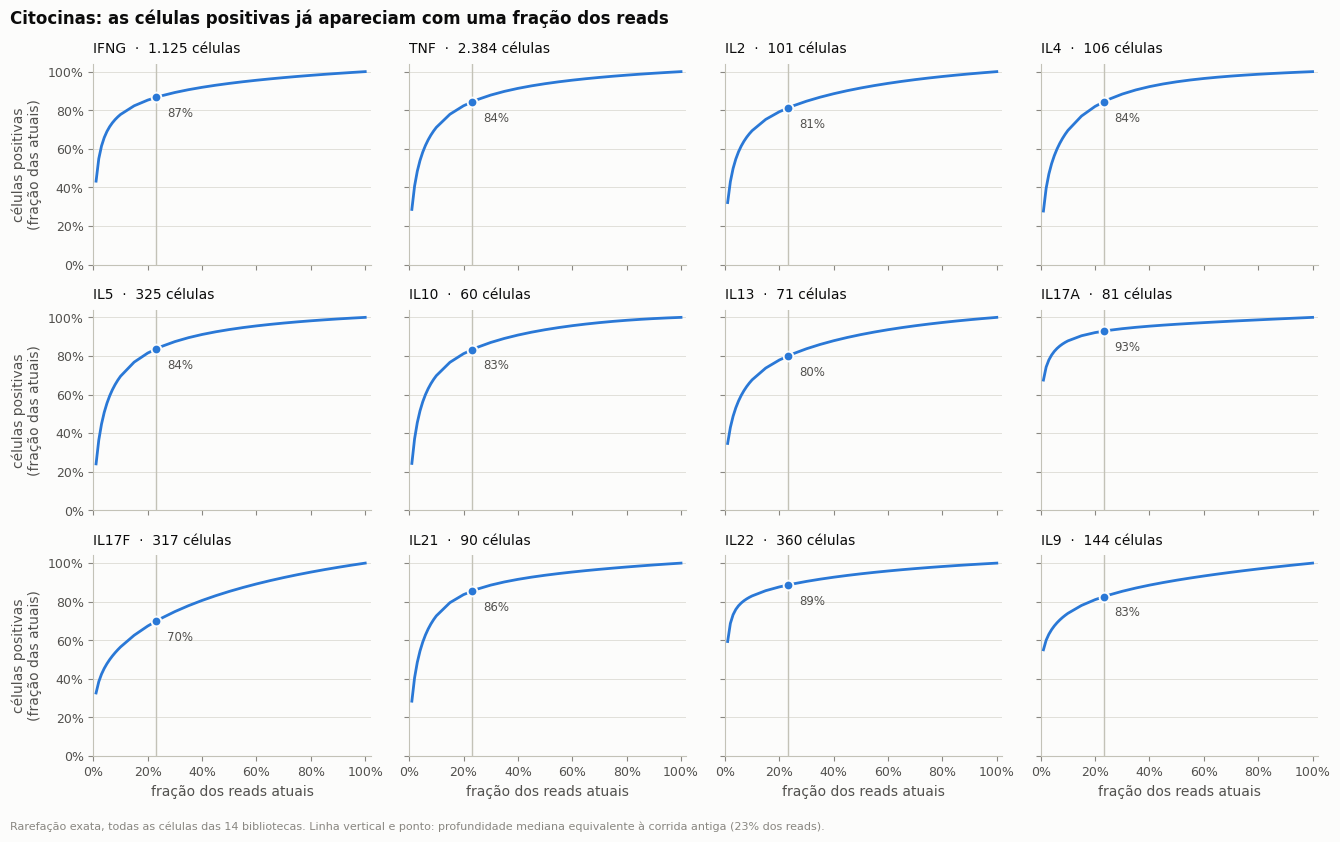

In [21]:
mostrar = [gname for gname in ["IFNG", "TNF", "IL2", "IL4", "IL5", "IL10", "IL13", "IL17A",
                               "IL17F", "IL21", "IL22", "IL9"] if gname in cit.index]
fgrid = np.r_[np.linspace(0.01, 0.1, 10), np.linspace(0.15, 1.0, 18)]
fig, axes = plt.subplots(3, 4, figsize=(13.5, 8.2), sharex=True, sharey=True)
curvas = []
f_ant_med = float(antiga["f_antiga"].median())
for ax, gname in zip(axes.ravel(), mostrar):
    p = painel[painel["gene"] == gname]
    h = np.bincount(p["reads"].to_numpy(dtype=np.int64))
    y = np.array([rf.expected_from_hist(h, f) for f in fgrid]) / len(p)
    ax.plot(fgrid, y, color=plotting.ACCENT, lw=2, zorder=3)
    ax.axvline(f_ant_med, color=INK["axis"], lw=1, zorder=1)
    ax.set_title(f"{gname}  ·  {F.n(len(p))} células", fontsize=10, fontweight="normal")
    ax.set_ylim(0, 1.04)
    ax.set_xlim(0, 1.02)
    curvas.append(pd.DataFrame({"gene": gname, "f": fgrid, "frac_das_positivas_atuais": y}))
    v = rf.expected_from_hist(h, f_ant_med) / len(p)
    ax.annotate(F.pct(v, 0), (f_ant_med, v), textcoords="offset points", xytext=(8, -14),
                fontsize=8.5, color=INK["secondary"])
    ax.plot(f_ant_med, v, "o", ms=7, mfc=plotting.ACCENT, mec=INK["surface"], mew=1.4, zorder=4)
for ax in axes[-1]:
    ax.set_xlabel("fração dos reads atuais")
    plotting.percent(ax, "x")
for ax in axes[:, 0]:
    ax.set_ylabel("células positivas\n(fração das atuais)")
    plotting.percent(ax)
fig.suptitle("Citocinas: as células positivas já apareciam com uma fração dos reads",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
plotting.note(fig, f"Rarefação exata, todas as células das {config.N_LIBRARIES} bibliotecas. Linha vertical e "
                   f"ponto: profundidade mediana equivalente à corrida antiga ({F.pct(f_ant_med, 0)} dos reads).")
plotting.savefig(fig, NB, "citocinas_rarefacao",
                 description="Células positivas por citocina em função da fração de reads",
                 data=pd.concat(curvas, ignore_index=True), data_index=False)
plt.show()

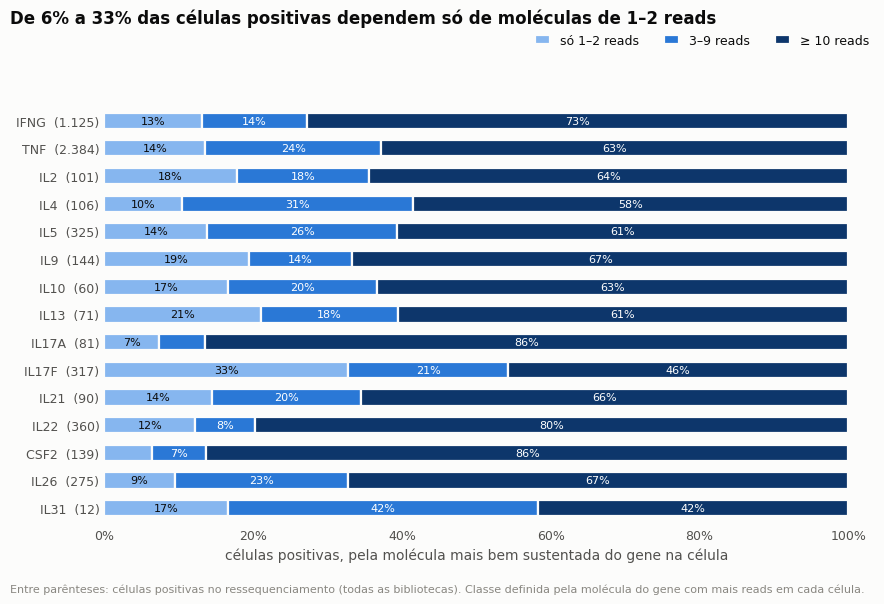

In [22]:
ordem = [gname for gname in config.CYTOKINES if gname in cit.index and cit.loc[gname, "celulas_positivas"] >= 10]
c16 = cit.loc[ordem]
frac = c16[["so_1_2_reads", "de_3_a_9_reads", "dez_ou_mais_reads"]].copy()
frac.columns = ["só 1–2 reads", "3–9 reads", "≥ 10 reads"]
frac.index = [f"{gname}  ({F.n(cit.loc[gname, 'celulas_positivas'])})" for gname in ordem]
fig, ax = plt.subplots(figsize=(8.8, 5.8))
plotting.stacked_barh(ax, frac, plotting.ORDINAL3)
ax.set_xlabel("células positivas, pela molécula mais bem sustentada do gene na célula")
fig.suptitle(f"De {F.pct(c16['so_1_2_reads'].min(), 0)} a {F.pct(c16['so_1_2_reads'].max(), 0)} das células "
             "positivas dependem só de moléculas de 1–2 reads",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.9))
hh, ll = ax.get_legend_handles_labels()
fig.legend(hh, ll, loc="upper right", ncol=3, bbox_to_anchor=(0.995, 0.95))
plotting.note(fig, "Entre parênteses: células positivas no ressequenciamento (todas as bibliotecas). "
                   "Classe definida pela molécula do gene com mais reads em cada célula.")
plotting.savefig(fig, NB, "citocinas_suporte",
                 description="Suporte de reads das células positivas por citocina",
                 data=c16[["celulas_positivas", "positivas_com_suporte", "so_1_2_reads",
                           "de_3_a_9_reads", "dez_ou_mais_reads"]])
plt.show()

In [23]:
metade = c16["positivas_com_metade_dos_reads"] / c16["celulas_positivas"]
pior = c16["so_1_2_reads"].idxmax()
print(f"citocinas com ≥ 10 células positivas: {len(c16)}")
print(f"  com metade dos reads já havia de {F.pct(metade.min(), 0)} a {F.pct(metade.max(), 0)} das "
      f"positivas atuais; a última duplicação acrescentou de "
      f"{F.pct(c16['ganho_ultima_duplicacao'].min(), 1, True)} a {F.pct(c16['ganho_ultima_duplicacao'].max(), 1, True)}")
print(f"  próxima duplicação, teto (Good–Toulmin, somando as {len(c16)} citocinas): "
      f"{F.n(c16['novas_ao_dobrar_teto'].sum())} pares célula–citocina sobre "
      f"{F.n(c16['celulas_positivas'].sum())} = "
      f"{F.pct(c16['novas_ao_dobrar_teto'].sum() / c16['celulas_positivas'].sum(), 1, True)} "
      "(por gene o estimador é ruidoso; vale o total)")
print(f"  células positivas sustentadas só por moléculas de 1–2 reads: "
      f"{F.pct(c16['so_1_2_reads'].min(), 0)} a {F.pct(c16['so_1_2_reads'].max(), 0)} "
      f"(mediana {F.pct(c16['so_1_2_reads'].median(), 0)}; fração global de moléculas de baixo suporte: "
      f"{F.pct(global_low, 0)}); maior em {pior}")
print(f"  exigindo molécula com ≥ {SUPORTE_MIN} reads:")
for gname in ["IFNG", "IL2", "IL4", "IL10", "IL13", "IL17A", "IL17F", "IL21"]:
    if gname in c16.index:
        r = c16.loc[gname]
        print(f"    {gname:6s} {F.n(r['celulas_positivas']):>6} → {F.n(r['positivas_com_suporte']):>6} células "
              f"({F.pct(r['pct_celulas'], 2)} → {F.pct(r['pct_com_suporte'], 2)})")

citocinas com ≥ 10 células positivas: 15
  com metade dos reads já havia de 85% a 97% das positivas atuais; a última duplicação acrescentou de +2,8% a +17,2%
  próxima duplicação, teto (Good–Toulmin, somando as 15 citocinas): 330 pares célula–citocina sobre 5.590 = +5,9% (por gene o estimador é ruidoso; vale o total)
  células positivas sustentadas só por moléculas de 1–2 reads: 6% a 33% (mediana 14%; fração global de moléculas de baixo suporte: 12%); maior em IL17F
  exigindo molécula com ≥ 3 reads:
    IFNG    1.125 →    978 células (2,97% → 2,58%)
    IL2       101 →     83 células (0,27% → 0,22%)
    IL4       106 →     95 células (0,28% → 0,25%)
    IL10       60 →     50 células (0,16% → 0,13%)
    IL13       71 →     56 células (0,19% → 0,15%)
    IL17A      81 →     75 células (0,21% → 0,20%)
    IL17F     317 →    213 células (0,84% → 0,56%)
    IL21       90 →     77 células (0,24% → 0,20%)


**Leitura.**

* *Profundidade.* A curva de células positivas é plana no trecho final: com
  metade dos reads já se via quase todo o conjunto de hoje, e dobrar de novo
  acrescentaria, no teto, poucos por cento de pares célula–citocina.
* *Suporte.* Uma parte das células positivas de cada citocina depende só de
  moléculas de 1–2 reads — a classe menos confiável da matriz, e exatamente a
  franja que a profundidade extra acrescenta. Ela é maior nas citocinas que
  algumas células expressam em dezenas de UMIs: nelas, uma célula com uma
  única molécula de 1–2 reads é o tipo de chamada que a seção 6 recomenda não
  aceitar.
* *Com o critério de suporte*, as frações de células positivas ficam ainda
  menores que as aparentes.

As células que de fato expressam citocina estão detectadas, com dezenas a
centenas de reads por célula. O que limita a análise é quantas são — e isso
não é uma variável do sequenciamento.

In [24]:
log.add("CRITICAL", "citocinas — profundidade não é o limite",
        "as células positivas para citocinas já estão detectadas; mais reads só acrescentam chamadas de 1–2 reads",
        evidence=f"nas {len(c16)} citocinas com ≥ 10 células positivas: com metade dos reads já havia "
                 f"{F.pct(metade.min(), 0)}–{F.pct(metade.max(), 0)} das positivas atuais; dobrar a "
                 f"profundidade acrescentaria, no teto, {F.n(c16['novas_ao_dobrar_teto'].sum())} pares "
                 f"célula–citocina sobre {F.n(c16['celulas_positivas'].sum())}; "
                 f"{F.pct(c16['so_1_2_reads'].min(), 0)}–{F.pct(c16['so_1_2_reads'].max(), 0)} das "
                 f"positivas (mediana {F.pct(c16['so_1_2_reads'].median(), 0)}) dependem só de "
                 "moléculas de 1–2 reads",
        impact="a baixa contagem de citocinas é frequência de células produtoras, não falha de "
               "detecção; nenhuma quantidade de sequenciamento destas bibliotecas a altera, e a "
               "fração aparente ainda superestima a fração com suporte",
        recommendation="redirecionar o esforço para o desenho experimental: enriquecer células "
                       "respondedoras, ajustar o estímulo e aumentar o número de células "
                       f"capturadas; nas análises, chamar positividade com ≥ {SUPORTE_MIN} reads na molécula")

## Problemas e conclusão

In [25]:
issues = log.save()
print(log.summary().to_string())
show(issues)

severity
CRITICAL    2
MAJOR       0
MINOR       2
INFO        3


severity,location,problem,evidence,impact,recommendation
CRITICAL,retorno de mais sequenciamento,"as bibliotecas estão no platô: a corrida antiga já tinha quase todos os UMIs, e dobrar de novo renderia poucos %","corrida antiga equivalente a 9%–32% dos reads atuais e já com 67%–96% dos UMIs atuais; última duplicação de profundidade: +3,1% de UMIs (mediana); próxima duplicação, teto de +2,6% (mediana, máx. +6,1%)",mais sequenciamento destas bibliotecas não muda o dado de forma útil,encerrar o sequenciamento destas bibliotecas; investir em novas capturas com mais células ou em enriquecimento
CRITICAL,citocinas — profundidade não é o limite,as células positivas para citocinas já estão detectadas; mais reads só acrescentam chamadas de 1–2 reads,"nas 15 citocinas com ≥ 10 células positivas: com metade dos reads já havia 85%–97% das positivas atuais; dobrar a profundidade acrescentaria, no teto, 330 pares célula–citocina sobre 5.590; 6%–33% das positivas (mediana 14%) dependem só de moléculas de 1–2 reads","a baixa contagem de citocinas é frequência de células produtoras, não falha de detecção; nenhuma quantidade de sequenciamento destas bibliotecas a altera, e a fração aparente ainda superestima a fração com suporte","redirecionar o esforço para o desenho experimental: enriquecer células respondedoras, ajustar o estímulo e aumentar o número de células capturadas; nas análises, chamar positividade com ≥ 3 reads na molécula"
MINOR,relação entre as duas corridas,a corrida antiga não é uma subamostra exata dos reads atuais: moléculas bem sustentadas hoje faltavam nela,"pares (célula, gene) com 1 molécula hoje, ausentes na corrida antiga — 6–10 reads: 33,4% (previsto 20,1%); 11–30 reads: 18,4% (previsto 6,3%); 31–100 reads: 5,3% (previsto 0,5%); no nível de célula a previsão é quase exata (correlação ≥ 0,994)",as duas corridas são amostragens parcialmente independentes das mesmas moléculas; combinar as contagens das duas não é simplesmente somar reads,"confirmar com quem sequenciou se a biblioteca foi recarregada ou preparada de novo a partir do cDNA; usar só o ressequenciamento daqui em diante, sem misturar matrizes das duas corridas"
MINOR,genes sustentados por reads isolados,"um grupo de genes tem contagem feita quase só de moléculas intrônicas com 1–2 reads, concentrada em poucas bibliotecas","988 genes com ≥ 200 moléculas e ≥ 50% de baixo suporte (global: 12,3%), fração exônica mediana de 1%; ex.: LINC00486, SLC26A3, STEAP1B, GPM6A, SNHG31; 0,37% das moléculas no total, mas 1,4% em PB21_NS (41% do total); 48 dos 85 genes que colapsaram entre corridas estão aqui",contagem que não se comporta como expressão e é específica de bibliotecas: candidata a entrar em HVGs e marcadores como efeito de batch,excluir esta lista da seleção de HVGs e não usar esses genes como marcadores (tables/C03_rarefacao_citocinas/genes_sustentados_por_reads_isolados.csv)
INFO,moléculas de baixo suporte (1–2 reads),[verificado] erro de UMI e de barcode explicam só uma minoria das moléculas de 1–2 reads,"4,7%–21,1% das moléculas em células têm até 2 reads; erro de UMI explica 0%–21% delas (mais nas bibliotecas mais saturadas); erro de barcode ≤ 0,93%",o restante mistura moléculas reais pouco amplificadas e leitura espúria (seção 6); um filtro geral por suporte removeria as duas coisas,não filtrar toda a matriz por suporte de reads; usar o suporte onde ele decide — chamada de positividade em genes de baixa contagem (seção 7) e exclusão dos genes dominados por reads isolados (seção 6)
INFO,troca de índice entre bibliotecas,[verificado e descartado] não há sinal de index hopping entre as 14 bibliotecas,"barcodes de fundo que são célula em biblioteca de outro paciente têm 0,83× as moléculas dos demais barcodes de fundo (mediana de 168 pares de bibliotecas)","a fração de reads fora de células vem de RNA ambiente e de barcodes de baixo conteúdo da própria biblioteca, não de contaminação entre bibliotecas no sequenciador",nenhuma
INFO,controle negativo — genes do Y em

## Conclusão

* A corrida antiga já continha a grande maioria dos UMIs; o
  ressequenciamento percorreu o platô da curva, e dobrar outra vez renderia
  poucos por cento.
* As duas corridas não são subamostras exatas uma da outra — vale confirmar
  se as bibliotecas foram preparadas de novo.
* Alguns por cento das moléculas têm 1–2 reads. Não há troca de índice entre
  bibliotecas, erro de barcode é desprezível nas células e erro de UMI
  explica só uma minoria delas.
* Um grupo de genes é sustentado quase só por reads intrônicos isolados,
  concentrado em poucas bibliotecas; o controle dos genes do Y em doadoras
  mostra que essa é a cara de uma molécula espúria. Esses genes devem ficar
  fora de HVGs e marcadores.
* Para as citocinas, quem expressa já está detectado. Mais profundidade só
  acrescenta chamadas de 1–2 reads, as menos confiáveis. O limite é o número
  de células que expressam.

In [26]:
feitos = io.manifest()
feitos = feitos[feitos["stage"] == NB][["name", "kind"]].drop_duplicates(keep="last")
print(f"{len(feitos)} artefatos gravados por este notebook:")
print(feitos.to_string(index=False))

31 artefatos gravados por este notebook:
                                name    kind
                          mol_resumo parquet
                         mol_suporte parquet
                      mol_hist_reads parquet
                       mol_rarefacao parquet
                    mol_limiar_reads parquet
              mol_ausencia_na_antiga parquet
                          mol_painel parquet
                           mol_genes parquet
                 mol_troca_de_indice parquet
                        mol_barcodes parquet
              suporte_por_biblioteca   table
              fig_reads_por_molecula  figure
              fig_reads_por_molecula   table
             corrida_antiga_na_curva   table
         fig_corrida_antiga_na_curva  figure
         fig_corrida_antiga_na_curva   table
          ausencia_na_corrida_antiga   table
      fig_ausencia_na_corrida_antiga  figure
      fig_ausencia_na_corrida_antiga   table
                  testes_de_artefato   table
              